# Comparación de modelos con PyCaret frente al Random Forest

El pipeline del proyecto (`src/models.py`) dejó al **Random Forest** como mejor
clasificador: **44.5 % de exactitud y 0.445 de F1 macro** sobre sectores
catastrales que nunca vio. Este notebook usa PyCaret para enfrentarlo a una
batería más amplia de algoritmos —boosting moderno, extra trees, discriminantes,
bayesianos, lineales— y responder una pregunta concreta:

> **¿Hay algún modelo que supere al Random Forest de forma real, o las
> diferencias caben dentro del ruido?**

**Tarea.** La misma del proyecto: predecir la categoría de valor de la manzana
(Bajo / Medio-Bajo / Medio-Alto / Alto) usando **solo las 12 variables de
ubicación**.

### Entorno

PyCaret fija versiones de scikit-learn y pandas incompatibles con el entorno del
pipeline, así que vive en su propio entorno conda (`pycaret`). Abre este notebook
con el kernel **Python (catastro-pycaret)**. Si no existe, desde Anaconda Prompt
en la raíz del repositorio:

```
conda create -n pycaret --override-channels -c conda-forge python=3.9.13 pip -y
conda activate pycaret
python -m pip install -r requirements-pycaret.txt
python -m ipykernel install --user --name catastro-pycaret --display-name "Python (catastro-pycaret)"
```

Requiere que las etapas 01 y 02 del pipeline ya se hayan ejecutado.

## Por qué no se usan los valores por defecto de PyCaret

PyCaret valida por defecto con **k-fold estratificado aleatorio**. En este
problema eso es un error: el valor del suelo tiene autocorrelación espacial
fuerte (Moran's I = 0.54), así que un corte aleatorio pone manzanas de la misma
cuadra a ambos lados y el modelo aprueba por vecindad, no por generalización.
En el pipeline esa diferencia infló el F1 macro hasta 0.12 puntos.

Aquí se replica exactamente el diseño de `src/models.py`:

| | Este notebook | `src/models.py` |
|---|---|---|
| Hold-out | 285 sectores disjuntos (`GroupShuffleSplit`, semilla 42) | igual |
| Validación cruzada | `GroupKFold` por sector catastral | igual |
| Métrica principal | F1 macro | igual |
| Variables | 12 de ubicación | igual |

Al final hay un experimento de control que corre los mismos modelos con la
validación aleatoria de PyCaret, para ver cuánto engaña.

## 0. Preparación

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, cohen_kappa_score,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GroupShuffleSplit

try:
    import pycaret
    from pycaret.classification import ClassificationExperiment
except ImportError as e:
    raise ImportError(
        "PyCaret no esta disponible en este kernel. Selecciona el kernel "
        "'Python (catastro-pycaret)' (ver la celda de introduccion)."
    ) from e

warnings.filterwarnings("ignore")
%matplotlib inline

# LightGBM imprime avisos por alias de parametros cuando se ajusta; se redirigen
# a un logger silencioso (no cambia ningun resultado)
import logging
try:
    import lightgbm
    _silencio = logging.getLogger("lightgbm_silencio")
    _silencio.addHandler(logging.NullHandler())
    _silencio.setLevel(logging.ERROR)
    _silencio.propagate = False
    lightgbm.register_logger(_silencio)
except ImportError:
    pass

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

import sklearn
print("pycaret", pycaret.__version__, "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__)
print("raiz del proyecto:", ROOT)

pycaret 3.3.2 | scikit-learn 1.4.2 | pandas 2.1.4
raiz del proyecto: C:\Users\Usuario\Proyectos\Catastro_ML


### Parámetros editables

In [2]:
FOLDS          = 5            # pliegues de GroupKFold por sector
METRICA        = "F1 macro"   # metrica para ordenar y ajustar
N_TOP          = 5            # modelos que pasan de la comparacion a la evaluacion final
N_TUNE         = 3            # cuantos de esos se ajustan con busqueda aleatoria
N_ITER_TUNING  = 10           # combinaciones probadas por modelo al ajustar
EXCLUIR        = []           # ids de PyCaret a omitir, p. ej. ["catboost"] si tarda
N_BOOT         = 2000         # remuestreos del bootstrap por sector
GUARDAR_TABLAS  = True        # escribe los CSV en outputs/tablas/
GUARDAR_FIGURAS = False       # escribe los PNG en outputs/figuras/

# Random Forest con los hiperparametros ganadores del pipeline
RF_PROYECTO = dict(n_estimators=400, min_samples_leaf=25)

TARGET = "valor_cod"
FEATURES = list(C.FEATURES_UBICACION)

# estilo
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 96, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold"})
COLOR_RF, COLOR_OTRO, COLOR_MEJOR, GRIS = "#d73027", "#4575b4", "#1a9850", "#9aa5ab"

NOMBRES = {
    "RandomForestClassifier": "Random Forest", "ExtraTreesClassifier": "Extra Trees",
    "LGBMClassifier": "LightGBM", "XGBClassifier": "XGBoost",
    "CatBoostClassifier": "CatBoost", "GradientBoostingClassifier": "Gradient Boosting",
    "AdaBoostClassifier": "AdaBoost", "DecisionTreeClassifier": "Arbol de decision",
    "KNeighborsClassifier": "KNN", "LogisticRegression": "Regresion logistica",
    "RidgeClassifier": "Ridge", "LinearDiscriminantAnalysis": "LDA",
    "QuadraticDiscriminantAnalysis": "QDA", "GaussianNB": "Naive Bayes",
    "SGDClassifier": "SVM lineal", "DummyClassifier": "Dummy",
    "VotingClassifier": "Ensamble (blend)", "StackingClassifier": "Ensamble (stack)",
}

def nombre(modelo):
    return NOMBRES.get(type(modelo).__name__, type(modelo).__name__)

def guardar_fig(fig, archivo):
    if GUARDAR_FIGURAS:
        fig.savefig(C.FIG_DIR / archivo, facecolor="white")

def guardar_tabla(tabla, archivo, **kw):
    if GUARDAR_TABLAS:
        tabla.to_csv(C.TAB_DIR / archivo, **kw)

## 1. Datos y partición espacial

Se reconstruye la partición exacta del pipeline y se comprueba contra
`outputs/resumen_modelado.json`. Si los tamaños no coinciden, la comparación con
el Random Forest del proyecto no sería justa y la celda lo avisa.

In [3]:
df = pd.read_csv(C.F_DATASET, dtype={"manzana": str, "sector": str})

gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=C.SEED)
idx_train, idx_test = next(gss.split(df[FEATURES], df[TARGET], groups=df["sector"]))
# se conserva el indice original de df: PyCaret une train y test y exige indices
# unicos, y alinea los grupos de GroupKFold por indice
train = df.iloc[idx_train]
test = df.iloc[idx_test]

resumen = json.loads((C.OUT_DIR / "resumen_modelado.json").read_text(encoding="utf-8"))
coincide = (len(train) == resumen["n_train"] and len(test) == resumen["n_test"])

print("train: %6d manzanas en %d sectores" % (len(train), train["sector"].nunique()))
print("test : %6d manzanas en %d sectores" % (len(test), test["sector"].nunique()))
print("sectores compartidos entre train y test:",
      len(set(train["sector"]) & set(test["sector"])))
print("particion identica a src/models.py:", "SI" if coincide else "NO - revisar")

pd.crosstab(test[TARGET].map(dict(enumerate(C.CLASES))), "manzanas en test")

train:  28538 manzanas en 855 sectores
test :  10210 manzanas en 285 sectores
sectores compartidos entre train y test: 0
particion identica a src/models.py: SI


col_0,manzanas en test
valor_cod,
Alto,2549
Bajo,2562
Medio-Alto,2588
Medio-Bajo,2511


## 2. Configuración del experimento

- `test_data` fija el hold-out de 285 sectores: PyCaret no vuelve a partir.
- `fold_strategy="groupkfold"` con los sectores como grupos: ningún sector cae
  a la vez en entrenamiento y validación dentro de la CV.
- `normalize=True`: necesario para los modelos lineales y KNN; a los árboles no
  les afecta.
- Se registran dos métricas del proyecto que PyCaret no trae: **F1 macro** (su
  F1 por defecto es ponderado) y **acierto ±1** (predicción exacta o en una
  categoría contigua).

In [4]:
# Las metricas van como funciones con sus argumentos ya fijados. PyCaret 3.3 con
# scikit-learn 1.4 pierde los kwargs de add_metric (p. ej. average="macro"): el
# scorer cae en average="binary", falla con datos multiclase y PyCaret devuelve
# 0.0 en silencio.
def f1_macro(y_true, y_pred, **kwargs):
    return f1_score(y_true, y_pred, average="macro")

def acierto_1(y_true, y_pred, **kwargs):
    # ravel: CatBoost entrega las predicciones como columna (n, 1) y, sin aplanar,
    # la resta se expande a una matriz n x n
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return float(np.mean(np.abs(y_true - y_pred) <= 1))

def nuevo_experimento(estrategia, grupos=None):
    exp = ClassificationExperiment()
    exp.setup(
        data=train[FEATURES + [TARGET]],
        test_data=test[FEATURES + [TARGET]],
        target=TARGET,
        fold_strategy=estrategia,
        fold=FOLDS,
        fold_groups=grupos,
        normalize=True,
        session_id=C.SEED,
        n_jobs=-1,
        verbose=False,
        html=False,
        system_log=False,      # sin log detallado; PyCaret igual crea logs.log al importarse (ignorado en git)
    )
    exp.add_metric("f1_macro", "F1 macro", f1_macro)
    exp.add_metric("acierto_1", "Acierto ±1", acierto_1)
    return exp

# PyCaret alinea los grupos por indice (groups.loc[X_train.index]), asi que se
# pasa la Serie con su indice y no un array
exp = nuevo_experimento("groupkfold", grupos=train["sector"])

X_tr, y_tr = exp.get_config("X_train"), exp.get_config("y_train")
g_tr = train["sector"].loc[X_tr.index]
compartidos = [len(set(g_tr.iloc[a]) & set(g_tr.iloc[b]))
               for a, b in exp.get_config("fold_generator").split(X_tr, y_tr, g_tr)]

print("validacion :", type(exp.get_config("fold_generator")).__name__, "x", FOLDS)
print("X_train    :", X_tr.shape, "| X_test:", exp.get_config("X_test").shape)
print("sectores compartidos entre entrenamiento y validacion, por pliegue:", compartidos)
exp.get_metrics()[["Name", "Greater is Better"]]

validacion : GroupKFold x 5
X_train    : (28538, 12) | X_test: (10210, 12)
sectores compartidos entre entrenamiento y validacion, por pliegue: [0, 0, 0, 0, 0]


,Name,Greater is Better
ID,,
acc,Accuracy,True
auc,AUC,True
recall,Recall,True
precision,Precision,True
f1,F1,True
kappa,Kappa,True
mcc,MCC,True
f1_macro,F1 macro,True
acierto_1,Acierto ±1,True


## 3. Comparación de todos los modelos

`compare_models` entrena cada algoritmo disponible con sus hiperparámetros por
defecto y lo evalúa con la CV espacial. La columna **TT (Sec)** es el tiempo de
entrenamiento por pliegue.

Ojo: el Random Forest que aparece aquí es el **de PyCaret por defecto**
(100 árboles, hojas de 1 muestra). No es el del proyecto, que usa 400 árboles y
hojas de 25; ese se evalúa aparte en la sección 4.

In [5]:
t0 = time.time()
mejores = exp.compare_models(sort=METRICA, n_select=N_TOP, exclude=EXCLUIR or None,
                             turbo=True, errors="ignore", verbose=False)
tabla_cv = exp.pull()
print("comparacion completa en %.1f min" % ((time.time() - t0) / 60))

guardar_tabla(tabla_cv, "t17_pycaret_comparacion_cv.csv")
tabla_cv.style.format(precision=4).background_gradient(subset=[METRICA], cmap="Greens")

comparacion completa en 3.5 min


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,F1 macro,Acierto ±1,TT (Sec)
lightgbm,Light Gradient Boosting Machine,0.4410,0.7025,0.4410,0.4463,0.4425,0.2534,0.2538,0.4422,0.8023,1.2500
catboost,CatBoost Classifier,0.4378,0.7045,0.4378,0.4390,0.4374,0.2493,0.2497,0.4370,0.7989,9.7640
gbc,Gradient Boosting Classifier,0.4347,0.0000,0.4347,0.4407,0.4363,0.2451,0.2457,0.4363,0.7961,8.3640
xgboost,Extreme Gradient Boosting,0.4345,0.6968,0.4345,0.4378,0.4356,0.2452,0.2454,0.4355,0.7963,0.6480
rf,Random Forest Classifier,0.4261,0.6911,0.4261,0.4238,0.4239,0.2343,0.2347,0.4233,0.7803,0.7920
ada,Ada Boost Classifier,0.4158,0.0000,0.4158,0.4223,0.4166,0.2203,0.2213,0.4165,0.7804,0.7880
et,Extra Trees Classifier,0.4133,0.6805,0.4133,0.4072,0.4079,0.2167,0.2176,0.4073,0.7650,0.3420
knn,K Neighbors Classifier,0.3974,0.6462,0.3974,0.4014,0.3973,0.1953,0.1959,0.3968,0.7677,1.3140
lr,Logistic Regression,0.3866,0.0000,0.3866,0.3810,0.3786,0.1816,0.1834,0.3788,0.7406,1.2400
lda,Linear Discriminant Analysis,0.3845,0.0000,0.3845,0.3793,0.3785,0.1786,0.1797,0.3788,0.7370,0.0340


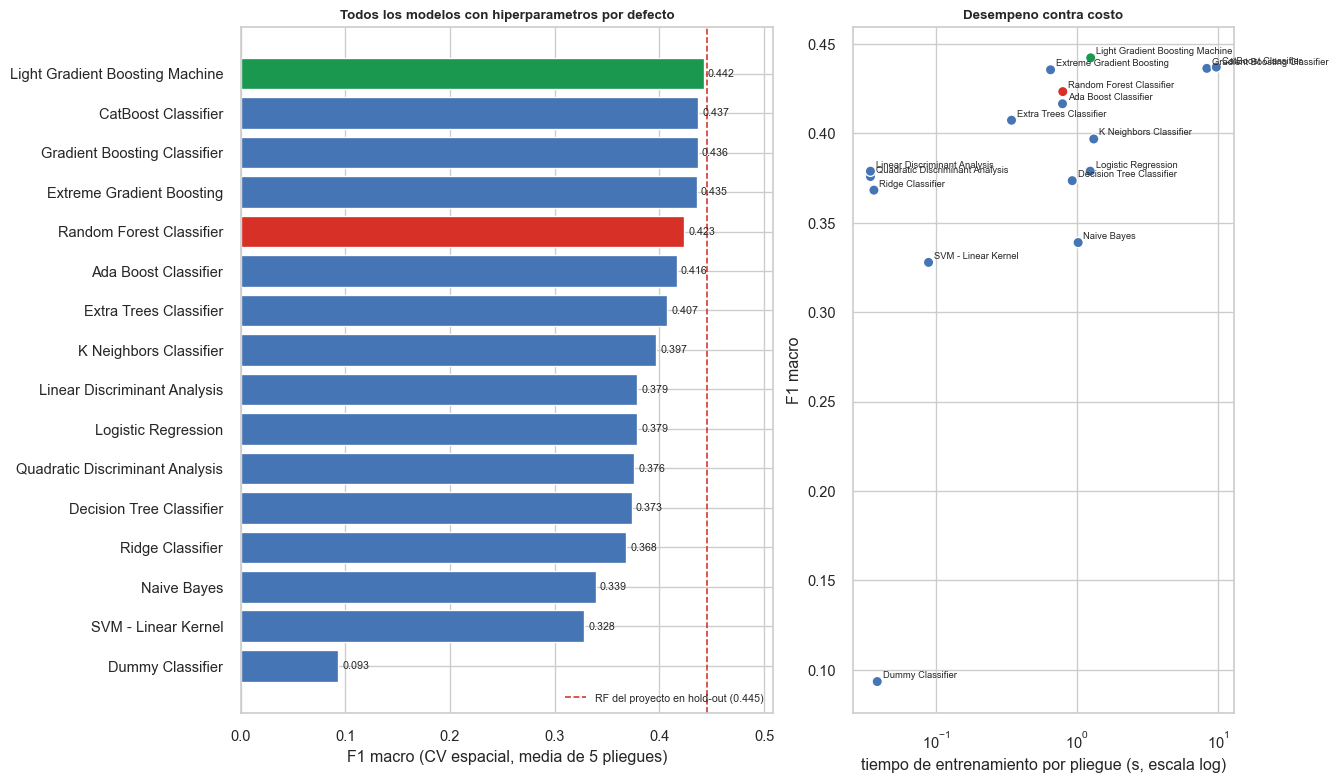

In [6]:
lb = tabla_cv.copy()
lb["id"] = lb.index
lb = lb.sort_values(METRICA)

colores = [COLOR_RF if i == "rf" else (COLOR_MEJOR if i == tabla_cv.index[0] else COLOR_OTRO)
           for i in lb["id"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(lb) + 1.5),
                         gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
ax.barh(lb["Model"], lb[METRICA], color=colores)
ax.axvline(resumen["metricas_test"][0]["f1_macro"], color=COLOR_RF, ls="--", lw=1.2,
           label="RF del proyecto en hold-out (%.3f)" % resumen["metricas_test"][0]["f1_macro"])
for y, v in enumerate(lb[METRICA]):
    ax.text(v + 0.004, y, "%.3f" % v, va="center", fontsize=8)
ax.set_xlabel("%s (CV espacial, media de %d pliegues)" % (METRICA, FOLDS))
ax.set_title("Todos los modelos con hiperparametros por defecto")
ax.legend(fontsize=8, loc="lower right")
ax.set_xlim(0, lb[METRICA].max() * 1.15)

ax = axes[1]
ax.scatter(lb["TT (Sec)"], lb[METRICA], c=colores, s=60, edgecolor="white", zorder=3)
for _, fila in lb.iterrows():
    ax.annotate(fila["Model"], (fila["TT (Sec)"], fila[METRICA]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("tiempo de entrenamiento por pliegue (s, escala log)")
ax.set_ylabel(METRICA)
ax.set_title("Desempeno contra costo")

fig.tight_layout()
guardar_fig(fig, "fig20_pycaret_comparacion.png")
plt.show()

## 4. El Random Forest del proyecto

Se entrena el Random Forest con los hiperparámetros del pipeline dentro del
mismo experimento, para compararlo en igualdad de condiciones con el resto.

In [7]:
rf_proyecto = exp.create_model("rf", verbose=False, **RF_PROYECTO)
cv_rf = exp.pull()

print("Random Forest del proyecto %s" % RF_PROYECTO)
print("  %s en CV espacial: %.4f +- %.4f"
      % (METRICA, cv_rf.loc["Mean", METRICA], cv_rf.loc["Std", METRICA]))
if "rf" in tabla_cv.index:
    print("  RF por defecto de PyCaret : %.4f" % tabla_cv.loc["rf", METRICA])
    print("  -> hojas de 25 frente a hojas de 1: %+.4f"
          % (cv_rf.loc["Mean", METRICA] - tabla_cv.loc["rf", METRICA]))
cv_rf.style.format(precision=4)

Random Forest del proyecto {'n_estimators': 400, 'min_samples_leaf': 25}
  F1 macro en CV espacial: 0.4375 +- 0.0052
  RF por defecto de PyCaret : 0.4233
  -> hojas de 25 frente a hojas de 1: +0.0142


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,F1 macro,Acierto ±1
Fold,,,,,,,,,
0,0.4560,0.7158,0.4560,0.4481,0.4509,0.2722,0.2727,0.4445,0.7828
1,0.4362,0.6946,0.4362,0.4460,0.4399,0.2472,0.2476,0.4428,0.8164
2,0.4357,0.7201,0.4357,0.4309,0.4320,0.2474,0.2480,0.4359,0.7984
3,0.4351,0.7004,0.4351,0.4283,0.4303,0.2456,0.2461,0.4314,0.7804
4,0.4325,0.7041,0.4325,0.4412,0.4348,0.2429,0.2435,0.4331,0.8013
Mean,0.4391,0.7070,0.4391,0.4389,0.4376,0.2511,0.2516,0.4375,0.7959
Std,0.0086,0.0095,0.0086,0.0080,0.0074,0.0107,0.0107,0.0052,0.0132


## 5. Ajuste de hiperparámetros de los mejores

Los modelos por defecto no compiten en igualdad con un Random Forest ya
ajustado. Se ajustan los `N_TUNE` mejores **retadores** con búsqueda aleatoria,
también bajo CV espacial, optimizando F1 macro. El Random Forest de PyCaret no
se ajusta: su versión ajustada ya existe y es la del proyecto.

Si un modelo no admite el ajuste con estas versiones de las librerías (le pasa a
CatBoost con scikit-learn 1.4), se sigue con su versión por defecto y queda
anotado en la tabla.

`choose_better=False` a propósito: si el ajuste empeora el modelo, se reporta
tal cual en vez de esconderlo.

In [8]:
retadores = [m for m in mejores if type(m).__name__ != "RandomForestClassifier"][:N_TUNE]

ajustados = []
filas_tuning = []
for modelo in retadores:
    t0 = time.time()
    antes = tabla_cv.loc[tabla_cv["Model"].index[mejores.index(modelo)], METRICA]
    try:
        ajustado = exp.tune_model(modelo, optimize=METRICA, n_iter=N_ITER_TUNING,
                                  choose_better=False, verbose=False)
        despues, nota = exp.pull().loc["Mean", METRICA], ""
    except Exception as e:
        # p. ej. CatBoost + scikit-learn 1.4: la busqueda no puede clonar el modelo
        # porque CatBoost renombra n_estimators. Se sigue con la version por defecto.
        ajustado, despues = None, np.nan
        nota = "no se pudo ajustar (%s)" % type(e).__name__
    ajustados.append(ajustado)
    filas_tuning.append({"modelo": nombre(modelo), "cv_por_defecto": antes,
                         "cv_ajustado": despues, "ganancia": despues - antes,
                         "minutos": (time.time() - t0) / 60, "nota": nota})
    print("%-22s %.4f -> %.4f  (%+.4f)  %.1f min  %s"
          % (nombre(modelo), antes, despues, despues - antes, (time.time() - t0) / 60, nota))

tabla_tuning = pd.DataFrame(filas_tuning)
tabla_tuning.style.format(precision=4)

LightGBM               0.4422 -> 0.4371  (-0.0051)  1.2 min  


CatBoost               0.4370 -> nan  (+nan)  0.1 min  no se pudo ajustar (ValueError)


Gradient Boosting      0.4363 -> 0.4403  (+0.0040)  4.0 min  


,modelo,cv_por_defecto,cv_ajustado,ganancia,minutos,nota
0,LightGBM,0.4422,0.4371,-0.0051,1.2368,
1,CatBoost,0.4370,nan,nan,0.0690,no se pudo ajustar (ValueError)
2,Gradient Boosting,0.4363,0.4403,0.0040,3.9580,


## 6. Ensamble de los mejores

Un ensamble promedia las probabilidades de varios modelos. Si los errores de los
modelos no están perfectamente correlacionados, puede superar a cada uno por
separado. Entra el Random Forest del proyecto y, de cada retador, la versión
—por defecto o ajustada— con mejor CV. La elección se hace con validación
cruzada, nunca mirando el hold-out.

In [9]:
componentes, etiquetas = [], []
for original, ajustado, fila in zip(retadores, ajustados, filas_tuning):
    usar_ajustado = ajustado is not None and fila["cv_ajustado"] > fila["cv_por_defecto"]
    componentes.append(ajustado if usar_ajustado else original)
    etiquetas.append(nombre(original) + (" ajustado" if usar_ajustado else " (por defecto)"))
componentes.append(rf_proyecto)
etiquetas.append("Random Forest (proyecto)")

blend = exp.blend_models(componentes, method="auto", optimize=METRICA,
                         choose_better=False, verbose=False)
cv_blend = exp.pull()
print("ensamble de:", ", ".join(etiquetas))
print("%s en CV espacial: %.4f +- %.4f"
      % (METRICA, cv_blend.loc["Mean", METRICA], cv_blend.loc["Std", METRICA]))

ensamble de: LightGBM (por defecto), CatBoost (por defecto), Gradient Boosting ajustado, Random Forest (proyecto)
F1 macro en CV espacial: 0.4435 +- 0.0053


## 7. Evaluación final en sectores no vistos

Hasta aquí todo se decidió con validación cruzada sobre el conjunto de
entrenamiento. La prueba real es el **hold-out: 10 210 manzanas en 285 sectores
que ningún modelo vio** al entrenar ni al ajustarse.

Como control, el Random Forest del proyecto debería reproducir aquí el 0.445
que obtuvo `src/models.py`.

In [10]:
candidatos = {}
cv_media = {}

for modelo, (id_modelo, fila) in zip(mejores, tabla_cv.head(N_TOP).iterrows()):
    etiqueta = nombre(modelo) + (" (por defecto)" if id_modelo == "rf" else "")
    candidatos[etiqueta] = modelo
    cv_media[etiqueta] = fila[METRICA]

for modelo, fila in zip(ajustados, filas_tuning):
    if modelo is None:        # el ajuste fallo; su version por defecto ya esta en la lista
        continue
    etiqueta = nombre(modelo) + " ajustado"
    candidatos[etiqueta] = modelo
    cv_media[etiqueta] = fila["cv_ajustado"]

candidatos["Ensamble (blend)"] = blend
cv_media["Ensamble (blend)"] = cv_blend.loc["Mean", METRICA]
candidatos["Random Forest (proyecto)"] = rf_proyecto
cv_media["Random Forest (proyecto)"] = cv_rf.loc["Mean", METRICA]

y_test = test[TARGET].astype(int).values
predicciones = {}
filas = []
for etiqueta, modelo in candidatos.items():
    pred = exp.predict_model(modelo, verbose=False)
    y_pred = pred["prediction_label"].loc[test.index].astype(int).values   # alineado por indice
    predicciones[etiqueta] = y_pred
    filas.append({
        "modelo": etiqueta,
        "cv_f1_macro": cv_media[etiqueta],
        "exactitud": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "kappa": cohen_kappa_score(y_test, y_pred),
        "acierto_1": acierto_1(y_test, y_pred),
    })

holdout = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
rf_ref = holdout.set_index("modelo").loc["Random Forest (proyecto)"]
holdout["dif_f1_vs_rf"] = holdout["f1_macro"] - rf_ref["f1_macro"]

print("RF del proyecto en hold-out: exactitud %.4f | F1 macro %.4f"
      % (rf_ref["exactitud"], rf_ref["f1_macro"]))
print("resultado en src/models.py : exactitud %.4f | F1 macro %.4f"
      % (resumen["metricas_test"][0]["exactitud"], resumen["metricas_test"][0]["f1_macro"]))

holdout.style.format(precision=4).background_gradient(subset=["f1_macro"], cmap="Greens")

RF del proyecto en hold-out: exactitud 0.4455 | F1 macro 0.4454
resultado en src/models.py : exactitud 0.4454 | F1 macro 0.4454


,modelo,cv_f1_macro,exactitud,f1_macro,kappa,acierto_1,dif_f1_vs_rf
0,Gradient Boosting ajustado,0.4403,0.4493,0.4527,0.2658,0.8155,0.0073
1,Ensamble (blend),0.4435,0.4496,0.4516,0.2661,0.8135,0.0062
2,LightGBM ajustado,0.4371,0.4476,0.4488,0.2635,0.8084,0.0034
3,LightGBM,0.4422,0.4457,0.4484,0.2610,0.8126,0.0030
4,CatBoost,0.4370,0.4468,0.4478,0.2625,0.8071,0.0024
5,Gradient Boosting,0.4363,0.4408,0.4461,0.2545,0.8169,0.0006
6,Random Forest (proyecto),0.4375,0.4455,0.4454,0.2607,0.8079,0.0000
7,XGBoost,0.4355,0.4398,0.4429,0.2531,0.8089,-0.0026
8,Random Forest (por defecto),0.4233,0.4313,0.4281,0.2418,0.7865,-0.0173


## 8. ¿La diferencia con el Random Forest es real?

Una ventaja de 0.005 en F1 puede ser suerte del hold-out. Para medirlo se usa un
**bootstrap por bloques de sector**: se remuestrean los 285 sectores completos
(no manzanas sueltas, porque las manzanas de un mismo sector no son
independientes), se recalcula el F1 macro de cada modelo y del Random Forest
sobre la misma muestra, y se guarda la diferencia.

Si el intervalo del 95 % de la diferencia **contiene el cero**, no hay evidencia
de que el modelo sea mejor ni peor que el Random Forest.

In [11]:
sectores_test = test["sector"].values
codigos, id_sector = np.unique(sectores_test, return_inverse=True)
S, K = len(codigos), len(C.CLASES)

def matrices_por_sector(y_true, y_pred):
    M = np.zeros((S, K, K))
    np.add.at(M, (id_sector, y_true, y_pred), 1)
    return M

def f1_macro_desde_matriz(cm):
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    fp = cm.sum(axis=-2) - tp
    fn = cm.sum(axis=-1) - tp
    with np.errstate(invalid="ignore", divide="ignore"):
        f1 = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn), 0.0)
    return f1.mean(axis=-1)

rng = np.random.default_rng(C.SEED)
pesos = np.stack([np.bincount(rng.integers(0, S, S), minlength=S) for _ in range(N_BOOT)])

f1_boot = {e: f1_macro_desde_matriz(np.einsum("bs,sij->bij", pesos,
                                              matrices_por_sector(y_test, p)))
           for e, p in predicciones.items()}
rf_boot = f1_boot["Random Forest (proyecto)"]

filas = []
for etiqueta in holdout["modelo"]:
    if etiqueta == "Random Forest (proyecto)":
        continue
    d = f1_boot[etiqueta] - rf_boot
    lo, hi = np.percentile(d, [2.5, 97.5])
    filas.append({"modelo": etiqueta, "dif_f1_vs_rf": d.mean(),
                  "ic95_inf": lo, "ic95_sup": hi,
                  "prob_supera_rf": (d > 0).mean(),
                  "veredicto": ("mejor que RF" if lo > 0 else
                                "peor que RF" if hi < 0 else "indistinguible de RF")})

significancia = pd.DataFrame(filas)
guardar_tabla(holdout.merge(significancia.drop(columns="dif_f1_vs_rf"), on="modelo", how="left"),
              "t18_pycaret_holdout.csv", index=False)
significancia.style.format(precision=4, subset=["dif_f1_vs_rf", "ic95_inf", "ic95_sup"]) \
                   .format("{:.1%}", subset=["prob_supera_rf"])

,modelo,dif_f1_vs_rf,ic95_inf,ic95_sup,prob_supera_rf,veredicto
0,Gradient Boosting ajustado,0.0073,-0.0049,0.0197,88.1%,indistinguible de RF
1,Ensamble (blend),0.0062,-0.0025,0.0145,93.3%,indistinguible de RF
2,LightGBM ajustado,0.0035,-0.0061,0.0134,76.3%,indistinguible de RF
3,LightGBM,0.0031,-0.0073,0.0136,72.4%,indistinguible de RF
4,CatBoost,0.0025,-0.0085,0.0138,67.1%,indistinguible de RF
5,Gradient Boosting,0.0007,-0.0151,0.0165,52.7%,indistinguible de RF
6,XGBoost,-0.0023,-0.0143,0.0100,36.1%,indistinguible de RF
7,Random Forest (por defecto),-0.0170,-0.0320,-0.0016,1.8%,peor que RF


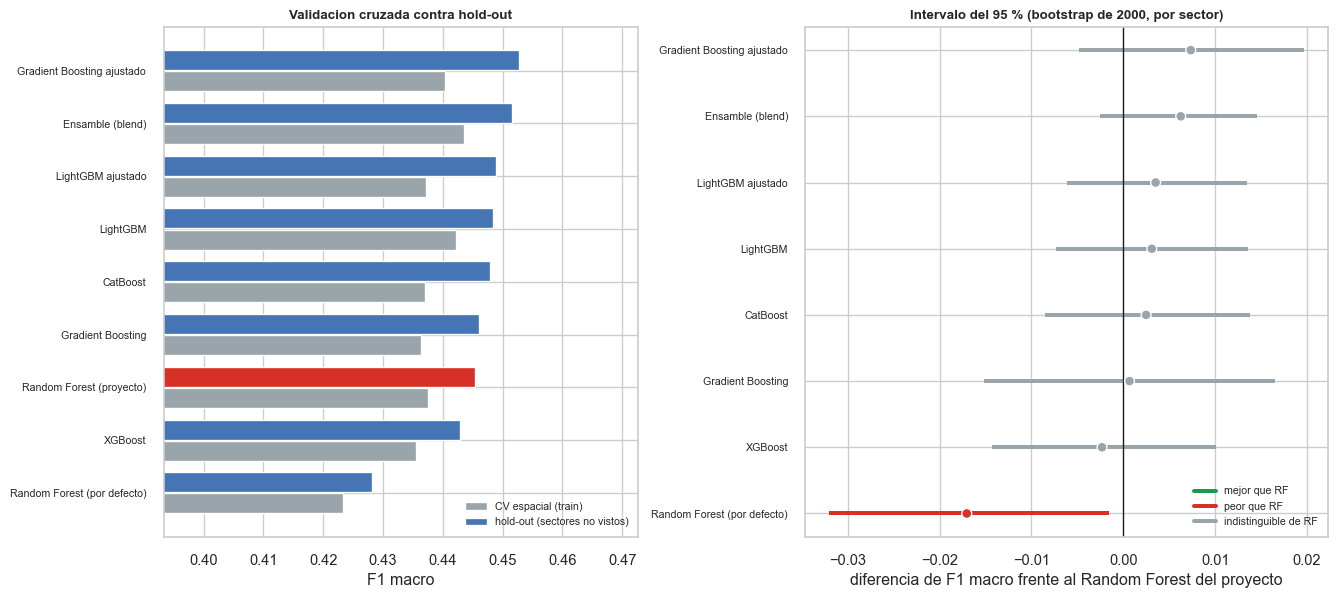

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 0.5 * len(holdout) + 1.8),
                         gridspec_kw={"width_ratios": [1, 1.1]})

# --- CV contra hold-out ---
ax = axes[0]
h = holdout.iloc[::-1]
y = np.arange(len(h))
ax.barh(y - 0.2, h["cv_f1_macro"], height=0.38, color=GRIS, label="CV espacial (train)")
ax.barh(y + 0.2, h["f1_macro"], height=0.38,
        color=[COLOR_RF if "proyecto" in m else COLOR_OTRO for m in h["modelo"]],
        label="hold-out (sectores no vistos)")
ax.set_yticks(y)
ax.set_yticklabels(h["modelo"], fontsize=8)
ax.set_xlim(h[["cv_f1_macro", "f1_macro"]].min().min() - 0.03,
            h[["cv_f1_macro", "f1_macro"]].max().max() + 0.02)
ax.set_xlabel("F1 macro")
ax.set_title("Validacion cruzada contra hold-out")
ax.legend(fontsize=8, loc="lower right")

# --- diferencia con RF e intervalo ---
ax = axes[1]
s = significancia.set_index("modelo").reindex([m for m in h["modelo"] if "proyecto" not in m])
y = np.arange(len(s))
color_v = {"mejor que RF": COLOR_MEJOR, "peor que RF": COLOR_RF,
           "indistinguible de RF": GRIS}
ax.hlines(y, s["ic95_inf"], s["ic95_sup"], color=[color_v[v] for v in s["veredicto"]], lw=3)
ax.scatter(s["dif_f1_vs_rf"], y, color=[color_v[v] for v in s["veredicto"]], s=55,
           zorder=3, edgecolor="white")
ax.axvline(0, color="k", lw=1)
ax.set_yticks(y)
ax.set_yticklabels(s.index, fontsize=8)
ax.set_xlabel("diferencia de F1 macro frente al Random Forest del proyecto")
ax.set_title("Intervalo del 95 %% (bootstrap de %d, por sector)" % N_BOOT)
handles = [plt.Line2D([], [], color=c, lw=3, label=v) for v, c in color_v.items()]
ax.legend(handles=handles, fontsize=8, loc="lower right")

fig.tight_layout()
guardar_fig(fig, "fig21_pycaret_holdout_vs_rf.png")
plt.show()

## 9. Dónde gana o pierde cada modelo

Comparar solo el F1 esconde el *tipo* de error. La matriz de diferencias
(mejor modelo − Random Forest) muestra en qué celdas el retador acierta más
(diagonal verde) o se equivoca más (fuera de la diagonal, verde también
significa más casos).

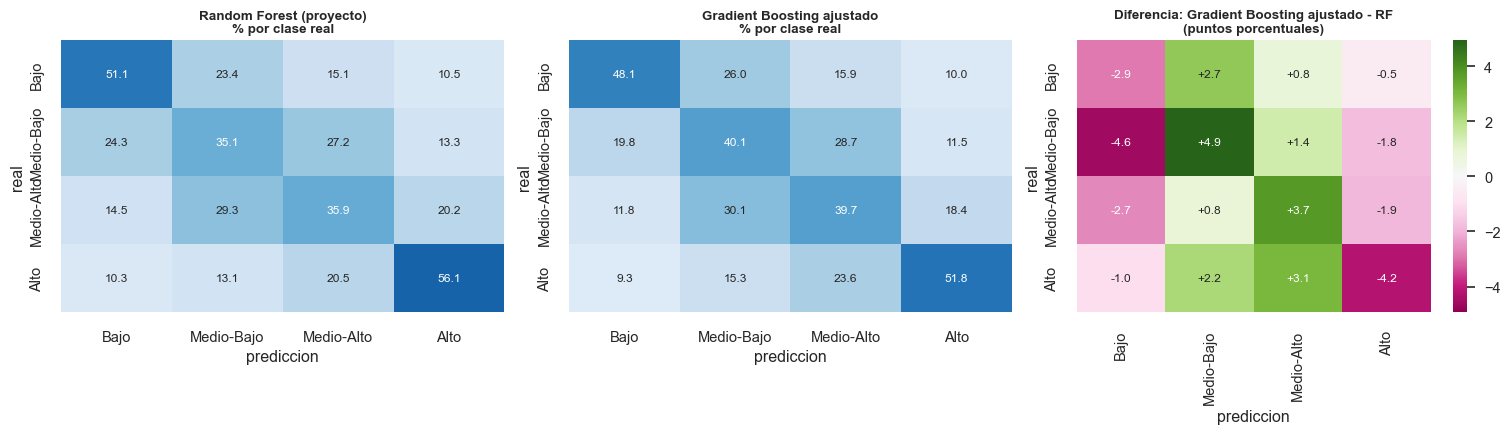

recall por clase (hold-out):


,Random Forest (proyecto),Gradient Boosting ajustado,diferencia
Bajo,51.05,48.13,-2.93
Medio-Bajo,35.13,40.06,4.94
Medio-Alto,35.94,39.68,3.75
Alto,56.06,51.82,-4.24


In [13]:
mejor_etiqueta = next(m for m in holdout["modelo"] if m != "Random Forest (proyecto)")

def matriz_pct(y_true, y_pred):
    return confusion_matrix(y_true, y_pred, labels=range(len(C.CLASES)), normalize="true") * 100

m_mejor = matriz_pct(y_test, predicciones[mejor_etiqueta])
m_rf = matriz_pct(y_test, predicciones["Random Forest (proyecto)"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, M, titulo in [(axes[0], m_rf, "Random Forest (proyecto)"),
                      (axes[1], m_mejor, mejor_etiqueta)]:
    sns.heatmap(M, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=70, cbar=False,
                xticklabels=C.CLASES, yticklabels=C.CLASES, ax=ax)
    ax.set_title("%s\n%% por clase real" % titulo)
    ax.set_xlabel("prediccion"); ax.set_ylabel("real")

lim = np.abs(m_mejor - m_rf).max()
sns.heatmap(m_mejor - m_rf, annot=True, fmt="+.1f", cmap="PiYG", center=0,
            vmin=-lim, vmax=lim, xticklabels=C.CLASES, yticklabels=C.CLASES, ax=axes[2])
axes[2].set_title("Diferencia: %s - RF\n(puntos porcentuales)" % mejor_etiqueta)
axes[2].set_xlabel("prediccion"); axes[2].set_ylabel("real")

fig.tight_layout()
guardar_fig(fig, "fig22_pycaret_matrices.png")
plt.show()

print("recall por clase (hold-out):")
pd.DataFrame({"Random Forest (proyecto)": np.diag(m_rf), mejor_etiqueta: np.diag(m_mejor),
              "diferencia": np.diag(m_mejor) - np.diag(m_rf)},
             index=C.CLASES).round(2)

## 10. ¿Usan la ubicación de la misma forma?

Importancia por permutación sobre el hold-out: cuánto cae el F1 macro al
desordenar cada variable. Se calcula igual para los dos modelos, así que es
comparable aunque sean algoritmos distintos.

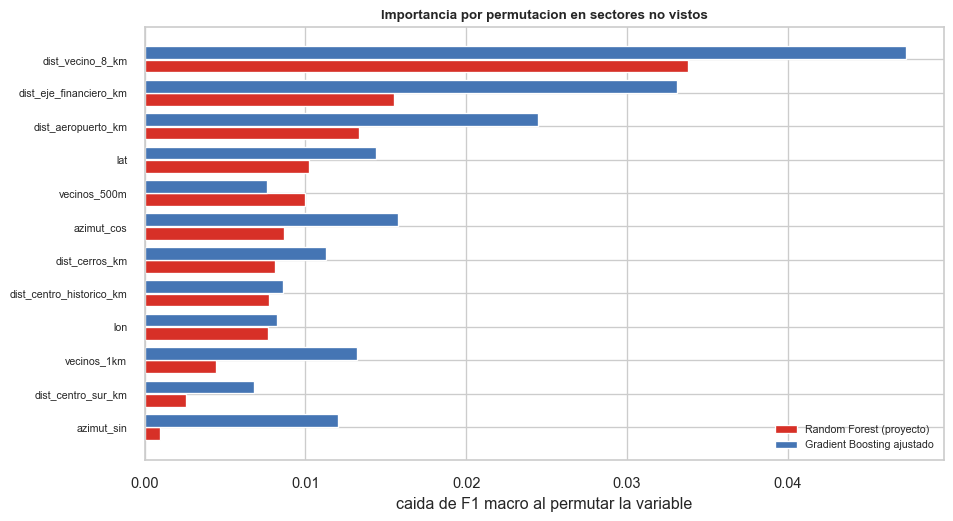

correlacion de rangos entre ambas importancias: rho = 0.699


In [14]:
X_test_t = exp.get_config("X_test_transformed")
y_test_t = exp.get_config("y_test_transformed")

importancias = {}
for etiqueta in ["Random Forest (proyecto)", mejor_etiqueta]:
    r = permutation_importance(candidatos[etiqueta], X_test_t, y_test_t, n_repeats=5,
                               scoring="f1_macro", random_state=C.SEED, n_jobs=-1)
    importancias[etiqueta] = pd.Series(r.importances_mean, index=X_test_t.columns)

imp = pd.DataFrame(importancias).sort_values("Random Forest (proyecto)")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(imp))
ax.barh(y - 0.2, imp["Random Forest (proyecto)"], height=0.38, color=COLOR_RF,
        label="Random Forest (proyecto)")
ax.barh(y + 0.2, imp[mejor_etiqueta], height=0.38, color=COLOR_OTRO, label=mejor_etiqueta)
ax.set_yticks(y); ax.set_yticklabels(imp.index, fontsize=8)
ax.set_xlabel("caida de F1 macro al permutar la variable")
ax.set_title("Importancia por permutacion en sectores no vistos")
ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "fig23_pycaret_importancias.png")
plt.show()

print("correlacion de rangos entre ambas importancias: rho = %.3f"
      % imp.corr(method="spearman").iloc[0, 1])

## 11. Control: lo que habría mostrado PyCaret por defecto

Mismos modelos, misma semilla, pero con el `stratifiedkfold` aleatorio que
PyCaret usa si no se le indica otra cosa. La distancia entre esa barra y el
hold-out es el optimismo que se habría reportado sin validación espacial.

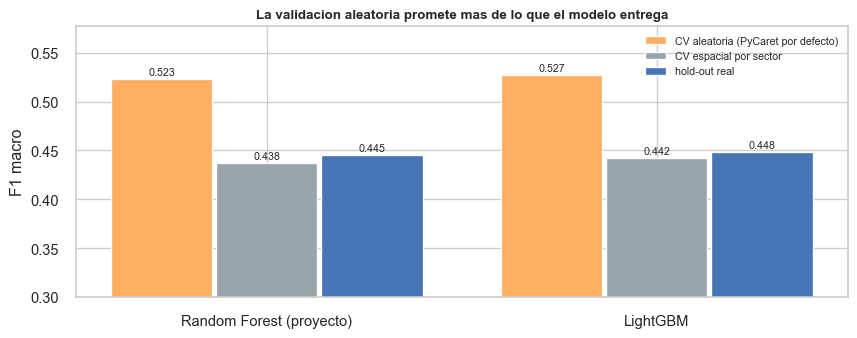

,modelo,cv_aleatoria,cv_espacial,holdout,optimismo_cv_aleatoria,error_cv_espacial
0,Random Forest (proyecto),0.5230,0.4375,0.4454,0.0776,-0.0079
1,LightGBM,0.5271,0.4422,0.4484,0.0787,-0.0062


In [15]:
exp_aleatorio = nuevo_experimento("stratifiedkfold")

id_mejor = tabla_cv.index[0]
control = []
for etiqueta, id_modelo, params in [
    ("Random Forest (proyecto)", "rf", RF_PROYECTO),
    (nombre(mejores[0]) + (" (por defecto)" if id_mejor == "rf" else ""), id_mejor, {}),
]:
    exp_aleatorio.create_model(id_modelo, verbose=False, **params)
    cv_aleatoria = exp_aleatorio.pull().loc["Mean", METRICA]
    control.append({
        "modelo": etiqueta,
        "cv_aleatoria": cv_aleatoria,
        "cv_espacial": cv_media[etiqueta],
        "holdout": holdout.set_index("modelo").loc[etiqueta, "f1_macro"],
    })

control = pd.DataFrame(control)
control["optimismo_cv_aleatoria"] = control["cv_aleatoria"] - control["holdout"]
control["error_cv_espacial"] = control["cv_espacial"] - control["holdout"]
guardar_tabla(control, "t19_pycaret_control_validacion.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(control))
for k, (col, color, etiqueta) in enumerate([("cv_aleatoria", "#fdae61", "CV aleatoria (PyCaret por defecto)"),
                                              ("cv_espacial", GRIS, "CV espacial por sector"),
                                              ("holdout", COLOR_OTRO, "hold-out real")]):
    ax.bar(x + (k - 1) * 0.27, control[col], width=0.26, color=color, label=etiqueta)
    for xi, v in zip(x, control[col]):
        ax.text(xi + (k - 1) * 0.27, v + 0.004, "%.3f" % v, ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(control["modelo"])
ax.set_ylim(0.3, control[["cv_aleatoria", "cv_espacial", "holdout"]].max().max() + 0.05)
ax.set_ylabel("F1 macro")
ax.set_title("La validacion aleatoria promete mas de lo que el modelo entrega")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
guardar_fig(fig, "fig24_pycaret_control_validacion.png")
plt.show()

control.style.format(precision=4)

## 12. Síntesis

In [16]:
rf = holdout.set_index("modelo").loc["Random Forest (proyecto)"]
top = holdout.iloc[0]
posicion_rf = int(holdout.index[holdout["modelo"] == "Random Forest (proyecto)"][0]) + 1
mejores_reales = significancia[significancia["veredicto"] == "mejor que RF"]
empates = significancia[significancia["veredicto"] == "indistinguible de RF"]

print("Modelos evaluados en hold-out : %d" % len(holdout))
print("Mejor F1 macro en hold-out    : %s (%.4f)" % (top["modelo"], top["f1_macro"]))
print("Random Forest del proyecto    : puesto %d de %d (%.4f)"
      % (posicion_rf, len(holdout), rf["f1_macro"]))
print()
if len(mejores_reales):
    print("Superan al Random Forest con evidencia (IC 95%% sobre cero):")
    for _, f in mejores_reales.iterrows():
        print("  - %-28s %+.4f  [%+.4f, %+.4f]"
              % (f["modelo"], f["dif_f1_vs_rf"], f["ic95_inf"], f["ic95_sup"]))
else:
    print("Ningun modelo supera al Random Forest con evidencia estadistica.")
print()
print("Indistinguibles del Random Forest: %s"
      % (", ".join(empates["modelo"]) if len(empates) else "ninguno"))
print("Optimismo de la CV aleatoria    : %+.3f a %+.3f puntos de F1"
      % (control["optimismo_cv_aleatoria"].min(), control["optimismo_cv_aleatoria"].max()))

Modelos evaluados en hold-out : 9
Mejor F1 macro en hold-out    : Gradient Boosting ajustado (0.4527)
Random Forest del proyecto    : puesto 7 de 9 (0.4454)

Ningun modelo supera al Random Forest con evidencia estadistica.

Indistinguibles del Random Forest: Gradient Boosting ajustado, Ensamble (blend), LightGBM ajustado, LightGBM, CatBoost, Gradient Boosting, XGBoost
Optimismo de la CV aleatoria    : +0.078 a +0.079 puntos de F1


### Cómo leer el resultado

- **La tabla de la sección 7 ordena; la de la sección 8 decide.** Un modelo
  arriba del Random Forest en la tabla pero con un intervalo que cruza el cero
  no es mejor: es un empate con un poco de suerte en este hold-out.
- **El techo lo pone la información, no el algoritmo.** Si boosting, extra
  trees, ensambles y ajuste fino terminan todos a pocas centésimas del Random
  Forest, el límite no es el modelo sino lo que la ubicación sola puede decir
  del valor. Para subir de ahí hacen falta variables nuevas (norma urbanística,
  uso del suelo, avalúos), no otro clasificador.
- **Criterio de desempate.** Entre modelos indistinguibles, conviene el más
  simple, rápido y estable: la columna TT (Sec) de la sección 3 y la desviación
  entre pliegues cuentan tanto como la media.